# Project 03: Customer Churn / Sales Trend Analysis
**Track:** Data Science & AI  
**Dataset:** Simulated e-commerce order data  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Context and business questions
A manager wants to understand:
1. Which months generate the most revenue, and how does revenue change month over month?
2. Which product categories contribute the most revenue and orders?
3. What share of revenue comes from the top 10% of customers?
4. What practical actions should the business consider based on the results?

> **Data note:** This notebook uses simulated practice data, not real customer or company records. The patterns and recommendations are for demonstrating analysis and must not be represented as real business findings.


## 1. Import libraries and generate sample orders
The seeded random generator makes the example reproducible. Each row represents one order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="colorblind")

rng = np.random.default_rng(42)
n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(
        rng.integers(0, 365, n), unit="D"
    ),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.30, 0.35, 0.20, 0.15]
    ),
    "amount": rng.gamma(shape=2.0, scale=600, size=n).round(2)
})

print("Dataset shape:", orders.shape)
display(orders.head())
orders.info()

Dataset shape: (2000, 4)


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB


## 2. Validate and inspect the data
Check missing values, duplicate rows, and basic statistics before analysis.

In [2]:
print("Missing values:")
display(orders.isna().sum().to_frame("missing_count"))

print("Duplicate rows:", int(orders.duplicated().sum()))
display(orders.describe(include="all").T)

Missing values:


,missing_count
order_date,0
customer_id,0
category,0
amount,0


Duplicate rows: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_date,2000,NaN,NaN,NaN,2025-07-01 22:45:07.200000,2025-01-01 00:00:00,2025-03-31 18:00:00,2025-07-02 00:00:00,2025-10-03 00:00:00,2025-12-31 00:00:00,NaN
customer_id,2000.0,NaN,NaN,NaN,151.1955,1.0,74.0,149.0,226.0,300.0,86.210007
category,2000,4,Fashion,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,2000.0,NaN,NaN,NaN,1202.116645,8.81,597.515,1005.87,1613.855,6276.09,826.961568


## 3. Feature engineering: extract date fields
Create month, weekday, and quarter fields from the order date. These features support time-based comparisons.

In [3]:
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="raise")
orders["month"] = orders["order_date"].dt.to_period("M")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.to_period("Q")

display(orders[["order_date", "month", "weekday", "quarter"]].head())

,order_date,month,weekday,quarter
0,2025-02-02,2025-02,Sunday,2025Q1
1,2025-10-10,2025-10,Friday,2025Q4
2,2025-08-27,2025-08,Wednesday,2025Q3
3,2025-06-10,2025-06,Tuesday,2025Q2
4,2025-06-08,2025-06,Sunday,2025Q2


## 4. Monthly revenue and month-over-month growth
Aggregate revenue by month, calculate percentage change, and identify the best and worst months in the generated sample.

In [4]:
monthly = orders.groupby("month", observed=True)["amount"].sum().sort_index()
monthly_growth = monthly.pct_change() * 100

monthly_summary = pd.DataFrame({
    "revenue": monthly,
    "mom_growth_percent": monthly_growth
})
display(monthly_summary.round(2))

best_month = monthly.idxmax()
worst_month = monthly.idxmin()
print(f"Best month by revenue: {best_month} — ${monthly.loc[best_month]:,.2f}")
print(f"Worst month by revenue: {worst_month} — ${monthly.loc[worst_month]:,.2f}")

,revenue,mom_growth_percent
month,,
2025-01,193341.87,NaN
2025-02,232027.20,20.01
2025-03,206327.14,-11.08
2025-04,197310.20,-4.37
2025-05,194090.49,-1.63
2025-06,221889.83,14.32
2025-07,221813.81,-0.03
2025-08,179783.75,-18.95
2025-09,180569.95,0.44


Best month by revenue: 2025-02 — $232,027.20
Worst month by revenue: 2025-08 — $179,783.75


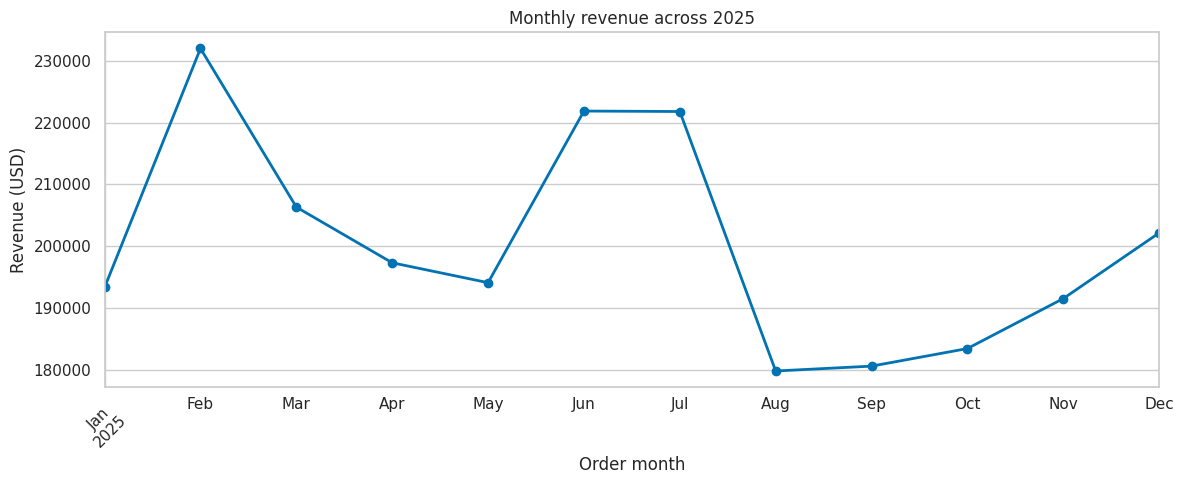

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(kind="line", marker="o", linewidth=2, ax=ax)
ax.set_title("Monthly revenue across 2025")
ax.set_xlabel("Order month")
ax.set_ylabel("Revenue (USD)")
ax.tick_params(axis="x", rotation=45)
ax.axvline(list(monthly.index).index(best_month), linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Category performance using groupby
Compare total revenue, average order value, and number of orders by category.

In [6]:
by_category = (
    orders.groupby("category", observed=True)["amount"]
    .agg(total_revenue="sum", average_order_value="mean", order_count="count")
    .sort_values("total_revenue", ascending=False)
)
display(by_category.round(2))

best_category = by_category["total_revenue"].idxmax()
print(
    f"Highest-revenue category: {best_category} "
    f"(${by_category.loc[best_category, 'total_revenue']:,.2f})."
)

,total_revenue,average_order_value,order_count
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


Highest-revenue category: Fashion ($853,984.93).


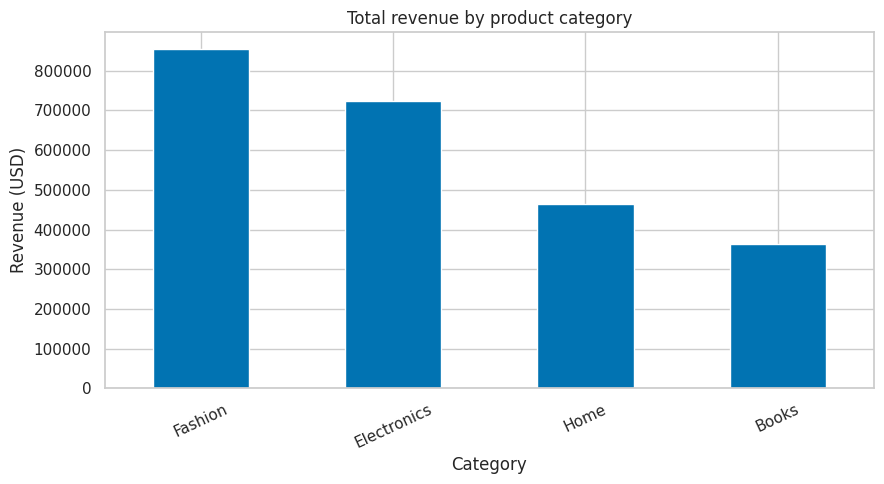

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
by_category["total_revenue"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)
ax.set_title("Total revenue by product category")
ax.set_xlabel("Category")
ax.set_ylabel("Revenue (USD)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 6. Pivot table: monthly revenue by category
The pivot table makes it easier to compare category performance across months.

In [8]:
monthly_category_pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    fill_value=0,
    observed=True
)
display(monthly_category_pivot.round(2))

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29186.89,62841.89,64665.99,36647.10
2025-02,34034.13,53564.89,86123.31,58304.87
2025-03,27843.58,58055.95,75138.67,45288.94
2025-04,26593.72,83335.56,57057.72,30323.20
2025-05,34425.63,57219.16,68569.90,33875.80
2025-06,32936.76,60037.00,85598.09,43317.98
2025-07,35582.36,72649.65,72647.96,40933.84
2025-08,32550.65,56690.46,71251.54,19291.10
2025-09,21824.73,60388.56,60231.75,38124.91


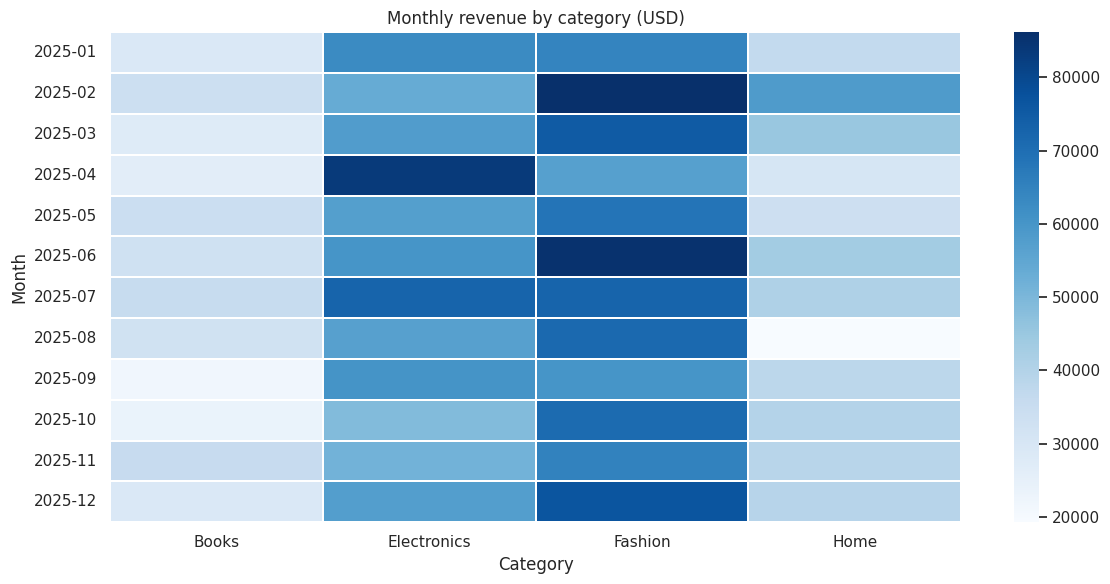

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    monthly_category_pivot,
    cmap="Blues",
    annot=False,
    linewidths=0.25,
    ax=ax
)
ax.set_title("Monthly revenue by category (USD)")
ax.set_xlabel("Category")
ax.set_ylabel("Month")
plt.tight_layout()
plt.show()

## 7. Customer value and the Pareto-style check
Calculate total spend per customer, then measure the share of revenue contributed by the top 10% of customers. This is a measurement of this simulated dataset, not a universal rule.

In [10]:
spend_by_customer = (
    orders.groupby("customer_id", observed=True)["amount"]
    .sum()
    .sort_values(ascending=False)
)

customer_count = len(spend_by_customer)
top_n = max(1, int(np.ceil(customer_count * 0.10)))
top_customers = spend_by_customer.head(top_n)
top_customer_revenue_share = top_customers.sum() / spend_by_customer.sum()

print("Unique customers:", customer_count)
print("Customers in top 10% group:", top_n)
print(f"Revenue share from top 10% of customers: {top_customer_revenue_share:.1%}")
display(spend_by_customer.head(10).to_frame("total_spend").round(2))

Unique customers: 300
Customers in top 10% group: 30
Revenue share from top 10% of customers: 18.9%


,total_spend
customer_id,
226,18140.15
51,18126.28
53,17994.36
131,17639.25
185,17222.49
282,17161.00
121,16564.87
98,15351.48
255,15313.47


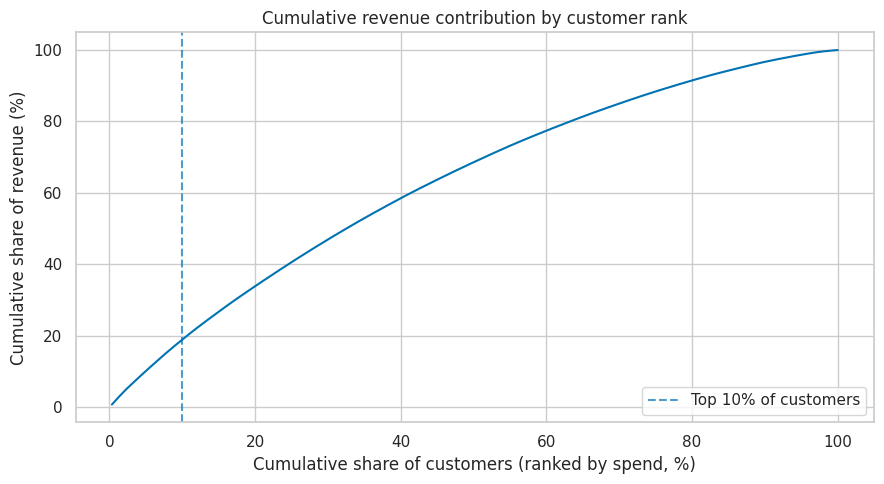

In [11]:
cumulative_share = spend_by_customer.cumsum() / spend_by_customer.sum()
customer_percent = np.arange(1, customer_count + 1) / customer_count * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(customer_percent, cumulative_share * 100)
ax.axvline(10, linestyle="--", alpha=0.7, label="Top 10% of customers")
ax.set_title("Cumulative revenue contribution by customer rank")
ax.set_xlabel("Cumulative share of customers (ranked by spend, %)")
ax.set_ylabel("Cumulative share of revenue (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Evidence-based findings and recommendations
The next cell generates three recommendations using the actual outputs of this simulated run. Review the values and wording before submitting.

In [12]:
best_month_revenue = monthly.loc[best_month]
worst_month_revenue = monthly.loc[worst_month]
best_cat_revenue = by_category.loc[best_category, "total_revenue"]
best_cat_share = best_cat_revenue / orders["amount"].sum()
top_share_pct = top_customer_revenue_share * 100

print("KEY FINDINGS")
print(f"1. Revenue was highest in {best_month} (${best_month_revenue:,.2f}) and lowest in {worst_month} (${worst_month_revenue:,.2f}).")
print(f"2. {best_category} was the highest-revenue category, contributing {best_cat_share:.1%} of total revenue.")
print(f"3. The top 10% of customers contributed {top_share_pct:.1f}% of total revenue.")

print("\nRECOMMENDATIONS")
print(
    f"1. Review the drivers of the peak month ({best_month}) and test whether its effective campaigns or product mix "
    "can be repeated in lower-revenue months."
)
print(
    f"2. Investigate inventory, margins, and conversion for {best_category}; prioritize it only if profitability "
    "and stock availability support the decision."
)
print(
    f"3. Test a measurable loyalty offer for high-spend customers, while monitoring repeat purchase rate and margin "
    f"because the top 10% account for {top_share_pct:.1f}% of simulated revenue."
)

KEY FINDINGS
1. Revenue was highest in 2025-02 ($232,027.20) and lowest in 2025-08 ($179,783.75).
2. Fashion was the highest-revenue category, contributing 35.5% of total revenue.
3. The top 10% of customers contributed 18.9% of total revenue.

RECOMMENDATIONS
1. Review the drivers of the peak month (2025-02) and test whether its effective campaigns or product mix can be repeated in lower-revenue months.
2. Investigate inventory, margins, and conversion for Fashion; prioritize it only if profitability and stock availability support the decision.
3. Test a measurable loyalty offer for high-spend customers, while monitoring repeat purchase rate and margin because the top 10% account for 18.9% of simulated revenue.


## 9. One-page business brief

### Context
This analysis uses a reproducible, simulated order dataset of 2,000 orders across four categories during 2025. It demonstrates revenue-trend and customer-value analysis; it is not real company performance.

### Key findings
Use the three numerical findings printed in Section 8. They are calculated from the dataset generated by this notebook.

### Recommendations
1. Investigate the peak month and test repeatable tactics during weaker months.
2. Review the highest-revenue category alongside gross margin, stock availability, and conversion before allocating more budget.
3. Pilot a loyalty offer for high-spend customers and measure incremental margin and repeat purchases.

### Next steps
Validate these patterns with real, authorized sales data; include discounts, refunds, costs, and customer acquisition costs before making commercial decisions. Compare multiple periods before assuming a trend will repeat.


## 10. Submission checklist
- [ ] Business question appears before the analysis.
- [ ] Dataset shape, data types, missing values, and duplicates are checked.
- [ ] Month, weekday, and quarter features are created.
- [ ] Monthly revenue, month-over-month growth, and a line chart are included.
- [ ] Categories are compared using groupby.
- [ ] A month-by-category pivot table is included.
- [ ] The top-10%-customer revenue share is calculated.
- [ ] Three specific recommendations are linked to numerical findings.
- [ ] Clearly state that the dataset is simulated.
- [ ] Restart the runtime and run all cells from top to bottom before submission.
